# Figure 4, Panel A

PCA analysis on RNA-seq datasets (log2(TPM+1)) for GM12878 treated with panel of stimuli (LPS, TNFa, IFNg, Dexamethasone, Doxorubicin, IL-2) at 6h. First two PCs are plotted, annotated with % of variance explained by each

*Output: PanelA_PCA.pdf*

# Setup

In [8]:
# load packages
library(tidyverse)
library(rtracklayer)
library(tximport)
library(DESeq2)
library(RColorBrewer)
library(here)
here::i_am("figures/Figure4/Panel_A/PanelA_PCA.ipynb")

sessionInfo()

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] here_1.0.2                  RColorBrewer_1.1-3         
 [3] DESeq2_1.38.3               SummarizedExperiment_1.28.0
 [5] Biobase_2.58.0              MatrixGenerics_1.10.0      
 [7] matrixStats_1.4.1           tximport_1.26.1            
 [9] rtracklayer_1.58.0          Gen

# load RSEM gene-level quantifications

In [9]:
path <- here(
    "inputs", "RSEM", "GM12878", "stimulus_panel"
)

files <- list.files(
    path,
    pattern   = "results",
    full.name = TRUE
)

files <- files[-grep("BRM|T2", files)]


#read in RSEM data
txi <- tximport(files=files, txIn=F, type="rsem")

#make coldata
col.data <- data.frame(Condition=c("Dex", "Dex", "DMSO", "DMSO", "Dox", "IFNy", "IFNy", "IL2", "IL2", "LPS", "LPS", "PBS", "PBS", "TNF", "TNF"),
              Replicate=c(1,2,1,2,1,1,2,1,2,1,2,1,2,1,2))

reading in files with read_tsv

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 
13 
14 
15 




# Generate row metadata from GENCODE v47 annotations

In [10]:
#GENCODE annotations
gtf.file <- here("inputs", "GENCODE", "gencode.v47.annotation.gtf.gz")
gencode <- import(gtf.file)
gencode <- gencode[which(gencode$type=="gene")]
#read in TSS coordinates w/ genes
gencode_tss <- read.delim(
                here("inputs", "GENCODE", "gencode.v47.annotation.transcripts_tss.1kb.bed"), 
                header=F, sep='\t')

#generate rowdata
row.data <- data.frame(gencode@elementMetadata)
rownames(row.data) <- row.data$gene_id
row.data$gene_id <- NULL
#generate column with cleaned ENSEMBL IDs
row.data$gene_id_base <- gsub("\\..*$", "", rownames(row.data)) 
#remove NA columns
row.data <- row.data[,colSums(is.na(row.data))<nrow(row.data)]
# add genome coordinates
row.data$chr <- as.character(gencode@seqnames)
row.data$start <- as.numeric(gencode@ranges@start)
row.data$end <- row.data$start + as.numeric(gencode@ranges@width)

# Filter genes to remove lowly expressed and 0-length entries

In [8]:
#filter txi object
nrow(txi$abundance)
#first, filter to exclude non-protein coding genes using the row metadata
txi$abundance <- txi$abundance[match(row.data$gene_id_base, gsub("\\..*$", "", rownames(txi$abundance))),] 
txi$counts <- txi$counts[match(row.data$gene_id_base, gsub("\\..*$", "", rownames(txi$counts))),]
txi$length <- txi$length[match(row.data$gene_id_base, gsub("\\..*$", "", rownames(txi$length))),]
nrow(txi$abundance)
#next, filter to remove lowly-expressed and 0-length genes
filt <- which(apply(txi$abundance,MARGIN=1,FUN=max) <= 1 | #genes with low expression (where max TPM for all samples is <=1)
                apply(txi$length, MARGIN=1,FUN=min)==0) #genes with weird annotations (length=0)

#filter out these genes from txi object
txi$abundance <- txi$abundance[-filt,]
txi$counts <- txi$counts[-filt,]
txi$length <- txi$length[-filt,]

#get rid of any NA rows
txi$counts <- txi$counts[-which(!rowSums(is.finite(txi$abundance))),]
txi$length <- txi$length[-which(!rowSums(is.finite(txi$abundance))),]
txi$abundance <- txi$abundance[-which(!rowSums(is.finite(txi$abundance))),]
nrow(txi$abundance)
     
#filter row metadata to match rows of filtered txi object
row.data <- row.data[match(gsub("\\..*$", "", 
                                rownames(txi$abundance)), 
                           row.data$gene_id_base),]
nrow(txi$abundance)
nrow(row.data)

[1] 59526

[1] 78724

[1] 15048

[1] 15048

[1] 15048

# Principal Component Analysis

In [9]:
#PCA analysis
dds <- DESeqDataSetFromTximport(txi, colData=col.data, design=~Condition)
vsd <- vst(dds, blind=FALSE)
pca <- prcomp(t(assay(vsd)))
var_explained <- 100*(pca$sdev^2)/(sum(pca$sdev^2))

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”
using counts and average transcript lengths from tximport

using 'avgTxLength' from assays(dds), correcting for library size



# Generate plot

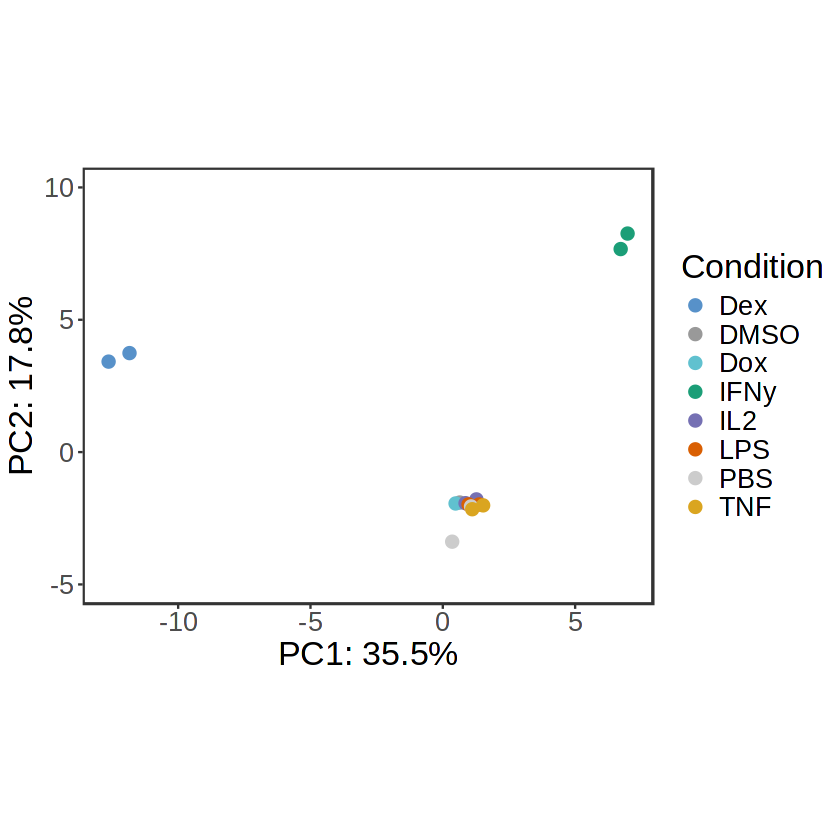

In [12]:
palette <- c("DMSO"="#999999", 
            "PBS"="#CCCCCC",
            "Dox"="#60C1CF",
            "Dex"="#5791c9",
            "IFNy"="#1B9E77",
            "IL2"="#7570B3",
            "LPS"="#D95F02",
            "TNF"="#daa520")

ggplot(pca$x, aes(x=PC1, y=PC2)) + 
    geom_point(size=3, aes(color=col.data$Condition)) + 
    coord_fixed() +
    scale_color_manual(values=palette, name="Condition") +
    theme_bw() +
    theme(text=element_text(size=20, color="black"), panel.grid=element_blank(), rect=element_rect(linewidth=1)) +
    xlab(paste0("PC1: ", format(var_explained[1], digits=3), "%")) +
    ylab(paste0("PC2: ", format(var_explained[2], digits=3), "%")) +
    scale_y_continuous(breaks=seq(-5,10,by=5), limits=c(-5,10))

ggsave("PanelA_PCA.pdf", width=5, height=4)